# FeatureHasher and DictVectorizer comparison: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/text/plot_hashing_vs_dict_vectorizer.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/text/plot_hashing_vs_dict_vectorizer.html)).

**Scenario:** documents are tokenized with a small regex tokenizer, turned into token-frequency dicts and
vectorized with `DictVectorizer`; the example then shows `FeatureHasher` (dict and raw-token input) and the
text vectorizers `CountVectorizer`, `HashingVectorizer` and `TfidfVectorizer`, and compares their speed.

**Adaptations:**
- **Data:** the example downloads 20 newsgroups (7 categories). This notebook builds a deterministic synthetic
  ASCII corpus instead (`np.random.RandomState(0)`, 7 topics, 140 documents of 20-60 words with punctuation and
  mixed case), so the run is offline. The Python reference runs the example code unchanged on that corpus.
- **Tokenization in Mojo:** the example's `tokenize` (`re.findall(r"\w+", doc)` + `lower()`) and `token_freqs`
  are re-implemented in the Mojo cell for ASCII text (word characters `[A-Za-z0-9_]`), so the whole
  vectorization runs natively. The corpus is ASCII, so both tokenizers agree token for token (checked below).
- **Dense output:** Moxie's `DictVectorizer` requires `sparse=False` (sparse output is deferred); the sklearn
  CSR result is compared through `.toarray()`. `DictVectorizer()` with the sparse default fails clearly (cell
  with `--expect-fail`).
- `vectorizer.vocabulary_["example"]` becomes `vocabulary_.column(FeatureKey("example"))`; the typed
  `FeatureKey`/`FeatureValue` rows replace Python dicts (documented adaptation).
- **Extra checks beyond the example:** `inverse_transform`, `restrict`, `clone`, refit and a
  `Pipeline(DictVectorizer(sparse=False), RidgeClassifier())` on the topic labels (composition).
- **Gaps:** `FeatureHasher`, `CountVectorizer`, `HashingVectorizer` and `TfidfVectorizer` are raising
  declarations in Moxie; their sections run only on the sklearn side, with `--expect-fail` proofs.
- Speed is printed for the sklearn run only; Moxie performance is not compared here.

**Determinism:** deterministic (fixed corpus seed, no randomness in any vectorizer).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_extraction/plot_hashing_vs_dict_vectorizer")

## 1. scikit-learn (Python reference)

Synthetic stand-in for `fetch_20newsgroups(subset="train", categories=categories)`.

In [2]:
import numpy as np

rng = np.random.RandomState(0)
topics = {
    "alt.atheism": "god belief religion atheism argument moral faith exist",
    "comp.graphics": "image graphics render pixel polygon color texture format",
    "comp.sys.ibm.pc.hardware": "drive disk controller bios card memory ide scsi",
    "misc.forsale": "sale price offer shipping condition sell new used",
    "rec.autos": "car engine dealer oil tire speed brake model",
    "sci.space": "space orbit nasa launch moon shuttle rocket mission",
    "talk.religion.misc": "christian bible church jesus truth moral faith god",
}
common = "the a is of and to in it that this for with example One two Example THE".split()
punct = [".", ",", "!", "?", "", "", "", "'s"]
categories = list(topics)
raw_data, labels = [], []
for i in range(140):
    label = i % len(categories)
    words = topics[categories[label]].split()
    n = rng.randint(20, 61)
    pool = np.array(words * 3 + common)
    tokens = [str(t) + punct[rng.randint(len(punct))] for t in rng.choice(pool, size=n)]
    raw_data.append(" ".join(tokens))
    labels.append(label)
labels = np.array(labels, dtype=np.int64)
data_size_mb = sum(len(s.encode("utf-8")) for s in raw_data) / 1e6
print(f"{len(raw_data)} documents - {data_size_mb:.3f}MB")
print(raw_data[0][:120])

140 documents - 0.034MB
atheism atheism. Example, belief atheism? moral. example? exist faith the's the's argument. belief! two? Example. exist,


In [3]:
import re


def tokenize(doc):
    """Extract tokens from doc (official example)."""
    return (tok.lower() for tok in re.findall(r"\w+", doc))


list(tokenize("This is a simple example, isn't it?"))

['this', 'is', 'a', 'simple', 'example', 'isn', 't', 'it']

In [4]:
from collections import defaultdict


def token_freqs(doc):
    """Extract a dict mapping tokens from doc to their occurrences (official example)."""
    freq = defaultdict(int)
    for tok in tokenize(doc):
        freq[tok] += 1
    return freq


token_freqs("That is one example, but this is another one")

defaultdict(int,
            {'that': 1,
             'is': 2,
             'one': 2,
             'example': 1,
             'but': 1,
             'this': 1,
             'another': 1})

In [5]:
from time import time

from sklearn.feature_extraction import DictVectorizer

dict_count_vectorizers = defaultdict(list)

t0 = time()
vectorizer = DictVectorizer()
X_dict = vectorizer.fit_transform(token_freqs(d) for d in raw_data)
duration = time() - t0
dict_count_vectorizers["vectorizer"].append(vectorizer.__class__.__name__ + "\non freq dicts")
dict_count_vectorizers["speed"].append(data_size_mb / duration)
print(f"done in {duration:.3f} s at {data_size_mb / duration:.1f} MB/s")
print(f"Found {len(vectorizer.get_feature_names_out())} unique terms")
print(type(vectorizer.vocabulary_), len(vectorizer.vocabulary_), vectorizer.vocabulary_["example"])

done in 0.003 s at 11.6 MB/s
Found 69 unique terms
<class 'dict'> 69 19


In [6]:
def n_nonzero_columns(X):
    """Number of columns with at least one non-zero value in a CSR matrix."""
    return len(np.unique(X.nonzero()[1]))


from sklearn.feature_extraction import FeatureHasher

t0 = time()
hasher = FeatureHasher(n_features=2**18)
X = hasher.transform(token_freqs(d) for d in raw_data)
duration = time() - t0
dict_count_vectorizers["vectorizer"].append(hasher.__class__.__name__ + "\non freq dicts")
dict_count_vectorizers["speed"].append(data_size_mb / duration)
print(f"done in {duration:.3f} s at {data_size_mb / duration:.1f} MB/s")
print(f"Found {n_nonzero_columns(X)} unique tokens")

t0 = time()
hasher = FeatureHasher(n_features=2**22)
X = hasher.transform(token_freqs(d) for d in raw_data)
duration = time() - t0
print(f"done in {duration:.3f} s at {data_size_mb / duration:.1f} MB/s")
print(f"Found {n_nonzero_columns(X)} unique tokens")

t0 = time()
hasher = FeatureHasher(n_features=2**18, input_type="string")
X = hasher.transform(tokenize(d) for d in raw_data)
duration = time() - t0
dict_count_vectorizers["vectorizer"].append(hasher.__class__.__name__ + "\non raw tokens")
dict_count_vectorizers["speed"].append(data_size_mb / duration)
print(f"done in {duration:.3f} s at {data_size_mb / duration:.1f} MB/s")
print(f"Found {n_nonzero_columns(X)} unique tokens")

done in 0.002 s at 17.7 MB/s
Found 69 unique tokens
done in 0.002 s at 18.5 MB/s
Found 69 unique tokens
done in 0.002 s at 18.8 MB/s
Found 69 unique tokens


CountVectorizer: done in 0.002 s at 16.5 MB/s
Found 67 unique terms
HashingVectorizer: done in 0.007 s at 4.7 MB/s
TfidfVectorizer: done in 0.002 s at 15.1 MB/s
Found 67 unique terms


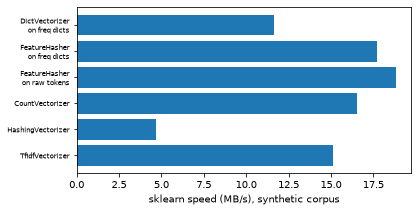

In [7]:
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer, TfidfVectorizer

for vectorizer_cls, kwargs in [(CountVectorizer, {}), (HashingVectorizer, {"n_features": 2**18}), (TfidfVectorizer, {})]:
    t0 = time()
    text_vectorizer = vectorizer_cls(**kwargs)
    text_vectorizer.fit_transform(raw_data)
    duration = time() - t0
    dict_count_vectorizers["vectorizer"].append(text_vectorizer.__class__.__name__)
    dict_count_vectorizers["speed"].append(data_size_mb / duration)
    print(f"{vectorizer_cls.__name__}: done in {duration:.3f} s at {data_size_mb / duration:.1f} MB/s")
    if hasattr(text_vectorizer, "get_feature_names_out"):
        print(f"Found {len(text_vectorizer.get_feature_names_out())} unique terms")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3), dpi=72)
y_pos = np.arange(len(dict_count_vectorizers["vectorizer"]))
ax.barh(y_pos, dict_count_vectorizers["speed"], align="center")
ax.set_yticks(y_pos)
ax.set_yticklabels(dict_count_vectorizers["vectorizer"], fontsize=7)
ax.invert_yaxis()
_ = ax.set_xlabel("sklearn speed (MB/s), synthetic corpus")

In [8]:
# Reference values for the Moxie comparison (extra checks beyond the example).
from sklearn.base import clone as sk_clone
from sklearn.linear_model import RidgeClassifier
from sklearn.pipeline import make_pipeline

sk_X = X_dict.toarray()
sk_names = DictVectorizer().fit(token_freqs(d) for d in raw_data).get_feature_names_out()
sk_tokens = np.array([" ".join(tokenize(d)) for d in raw_data])
dv = DictVectorizer(sparse=False).fit([token_freqs(d) for d in raw_data])
sk_inverse = dv.inverse_transform(sk_X[:1])[0]
sk_inv_keys = np.array(list(sk_inverse.keys()))
sk_inv_values = np.array(list(sk_inverse.values()))
support = sk_X.sum(axis=0) >= np.median(sk_X.sum(axis=0))
sk_restricted = DictVectorizer(sparse=False).fit([token_freqs(d) for d in raw_data])
sk_restricted.restrict(support)
sk_restricted_names = sk_restricted.get_feature_names_out()
sk_restricted_X = sk_restricted.transform([token_freqs(d) for d in raw_data])
sk_unsorted = DictVectorizer(sparse=False, sort=False).fit([token_freqs(d) for d in raw_data]).get_feature_names_out()
pipe = make_pipeline(DictVectorizer(sparse=False), RidgeClassifier())
pipe.fit([token_freqs(d) for d in raw_data[:100]], labels[:100])
sk_pipe_pred = pipe.predict([token_freqs(d) for d in raw_data[100:]])
sk_pipe_decision = pipe.decision_function([token_freqs(d) for d in raw_data[100:]])
print("restricted to", len(sk_restricted_names), "features; pipeline accuracy",
      pipe.score([token_freqs(d) for d in raw_data[100:]], labels[100:]))
nb.share(docs=np.array(raw_data), labels=labels, support=support)

restricted to 35 features; pipeline accuracy 1.0


## 2. Moxie (native Mojo)

Tokenization, frequency counting, vectorization, inverse transform, restriction and the pipeline all run in Mojo.
Python only supplies the document strings, labels and the restriction mask.

In [9]:
%%mojo dict_vectorizer
from numojo import NDArray, Shape
from moxie.base import clone
from moxie.feature_extraction import DictVectorizer
from moxie.feature_extraction._dict_vectorizer import FeatureBatch, FeatureRow, FeatureEntry, FeatureKey, FeatureValue
from moxie.linear_model import RidgeClassifier
from moxie.pipeline import Pipeline
from moxie_nb_io import load, load_strings, save, save_floats, save_ints, save_strings


def is_word(b: UInt8) -> Bool:
    return (b >= 48 and b <= 57) or (b >= 65 and b <= 90) or (b >= 97 and b <= 122) or b == 95


def tokenize(doc: String) -> List[String]:
    """ASCII equivalent of re.findall(r"\\w+", doc) followed by lower()."""
    var tokens = List[String]()
    var current = String("")
    for b in doc.as_bytes():
        if is_word(b):
            current += chr(Int(b))
        elif current.byte_length() > 0:
            tokens.append(current.lower())
            current = String("")
    if current.byte_length() > 0:
        tokens.append(current.lower())
    return tokens^


def token_freqs(doc: String) raises -> FeatureRow:
    var counts = Dict[String, Int]()
    var order = List[String]()
    for tok in tokenize(doc):
        if tok not in counts:
            counts[tok] = 0
            order.append(tok)
        counts[tok] = counts[tok] + 1
    var row = FeatureRow()
    for tok in order:
        row.append(FeatureEntry(FeatureKey(tok), FeatureValue(Int64(counts[tok]))))
    return row^


def batch(docs: List[String], start: Int, stop: Int) raises -> FeatureBatch:
    var rows = FeatureBatch()
    for i in range(start, stop):
        rows.append(token_freqs(docs[i]))
    return rows^


def main() raises:
    var docs = load_strings("docs")
    var labels = load[DType.int64]("labels")
    var support_array = load[DType.bool]("support")
    var joined = List[String]()
    for d in docs:
        var line = String("")
        for tok in tokenize(d):
            line += (" " if line.byte_length() > 0 else "") + tok
        joined.append(line)
    save_strings("tokens", joined)

    var rows = batch(docs, 0, len(docs))
    var vectorizer = DictVectorizer(sparse=False)
    var X = vectorizer.fit_transform(rows)
    print("Found", len(vectorizer.get_feature_names_out()), "unique terms")
    print("vocabulary_['example'] =", vectorizer.vocabulary_.column(FeatureKey("example")))
    save("X", X)
    save_strings("names", vectorizer.get_feature_names_out())
    var example = List[Int]()
    example.append(vectorizer.vocabulary_.column(FeatureKey("example")))
    example.append(vectorizer.vocabulary_.column(FeatureKey("not-a-token")))
    save_ints("example_column", example)

    # inverse_transform of the first row: dict from FeatureKey to value.
    var first = vectorizer.transform(rows[0].copy())
    var inverse = vectorizer.inverse_transform(first)
    var inv_keys = List[String]()
    var inv_values = List[Float64]()
    for item in inverse[0].items():
        inv_keys.append(item.key.text)
        inv_values.append(Float64(item.value))
    save_strings("inv_keys", inv_keys)
    save_floats("inv_values", inv_values)

    # Unfitted clone, then restrict the fitted copy with the shared boolean mask.
    var restricted = clone(vectorizer)
    print("clone fitted:", restricted.__sklearn_is_fitted__())
    _ = restricted.fit(rows)
    var X_restricted = restricted.restrict(support_array).transform(rows)
    save("X_restricted", X_restricted)
    save_strings("restricted_names", restricted.get_feature_names_out())
    # The original keeps its full vocabulary.
    save_ints("original_width", [len(vectorizer.get_feature_names_out())])

    # Parameter change then refit replaces learned state.
    _ = vectorizer.set_params(sort=False).fit(rows)
    save_strings("unsorted_names", vectorizer.get_feature_names_out())

    # Composition: Pipeline(DictVectorizer(sparse=False), RidgeClassifier()).
    var y_train = NDArray[DType.int64](Shape(100))
    for i in range(100):
        y_train.unsafe_set(i, labels.unsafe_get(i))
    var pipe = Pipeline(DictVectorizer(sparse=False), RidgeClassifier())
    _ = pipe.fit(batch(docs, 0, 100), y_train)
    var test_rows = batch(docs, 100, len(docs))
    save("pipe_pred", pipe.predict(test_rows))
    save("pipe_decision", pipe.decision_function(test_rows))

Found 69 unique terms
vocabulary_['example'] = 19
clone fitted: False


### Unsupported: sparse default and the hashing / text vectorizers

Each cell below must fail with a clear error.

In [10]:
%%mojo dict_vectorizer_sparse_default --expect-fail
from moxie.feature_extraction import DictVectorizer
from moxie.feature_extraction._dict_vectorizer import FeatureBatch, FeatureRow, FeatureEntry, FeatureKey, FeatureValue


def main() raises:
    var row = FeatureRow()
    row.append(FeatureEntry(FeatureKey("example"), FeatureValue(Int64(1))))
    var rows = FeatureBatch()
    rows.append(row^)
    var vectorizer = DictVectorizer()  # sklearn default sparse=True -> CSR output
    _ = vectorizer.fit_transform(rows)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: sparse output deferred; select sparse=False



In [11]:
%%mojo feature_hasher --expect-fail
from moxie.feature_extraction import FeatureHasher


def main() raises:
    var hasher = FeatureHasher(n_features=2**18)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: FeatureHasher.__init__ is an API scaffold



In [12]:
%%mojo count_vectorizer --expect-fail
from moxie.feature_extraction.text import CountVectorizer


def main() raises:
    var vectorizer = CountVectorizer()

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: CountVectorizer.__init__ is an API scaffold



In [13]:
%%mojo tfidf_vectorizer --expect-fail
from moxie.feature_extraction.text import TfidfVectorizer


def main() raises:
    var vectorizer = TfidfVectorizer()

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: TfidfVectorizer.__init__ is an API scaffold



## 3. Side by side and parity

In [14]:
import moxie_nb

mx = nb.results["dict_vectorizer"]
moxie_nb.side_by_side(sklearn=sk_X[:3, :8], moxie=mx["X"][:3, :8])
nb.compare("tokenize (regex \\w+ vs native ASCII)", sk_tokens, mx["tokens"], exact=True)
nb.compare("get_feature_names_out (sorted)", sk_names, mx["names"], exact=True)
nb.compare("fit_transform (dense vs CSR.toarray())", sk_X, mx["X"], exact=True,
           reason="integer counts summed in Float64; exact")
nb.compare("vocabulary_['example'] / unknown key", [vectorizer.vocabulary_["example"], -1], mx["example_column"], exact=True)
order = np.argsort(sk_inv_keys)
morder = np.argsort(mx["inv_keys"])
nb.compare("inverse_transform keys (row 0)", sk_inv_keys[order], mx["inv_keys"][morder], exact=True)
nb.compare("inverse_transform values (row 0)", sk_inv_values[order], mx["inv_values"][morder], exact=True)
nb.compare("restrict(mask) feature names", sk_restricted_names, mx["restricted_names"], exact=True)
nb.compare("restrict(mask) transform", sk_restricted_X, mx["X_restricted"], exact=True)
nb.compare("restrict leaves the original width", [len(sk_names)], mx["original_width"], exact=True)
nb.compare("set_params(sort=False) + refit names (first-seen order)", sk_unsorted, mx["unsorted_names"], exact=True)
nb.compare("Pipeline(DictVectorizer, RidgeClassifier).predict", sk_pipe_pred, mx["pipe_pred"], exact=True)
nb.compare("Pipeline decision_function", sk_pipe_decision, mx["pipe_decision"], rtol=1e-8, atol=1e-10,
           reason="Ridge closed-form solve on the same count matrix; LAPACK vs native factorisation "
                  "rounding differs at ~1e-13")
nb.note("DictVectorizer() sparse default", "GAP",
        "sparse=True (sklearn default, CSR output) raises a deferred-capability error; use sparse=False")
nb.note("FeatureHasher (dict and string input)", "GAP",
        "raising declaration: 'NotImplementedError: FeatureHasher.__init__ is an API scaffold'")
nb.note("CountVectorizer / HashingVectorizer / TfidfVectorizer", "GAP",
        "raising declarations in moxie.feature_extraction.text; no tokenizer, hashing or TF-IDF engine")
nb.note("Speed comparison", "SKIP", "timings shown for sklearn only; Moxie performance is not measured here")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
tokenize (regex \w+ vs native ASCII),PASS,"(140,)","(140,)",,,exact,0 mismatches,
get_feature_names_out (sorted),PASS,"(69,)","(69,)",,,exact,0 mismatches,
fit_transform (dense vs CSR.toarray()),PASS,"(140, 69)","(140, 69)",,,exact,0 mismatches,integer counts summed in Float64; exact
vocabulary_['example'] / unknown key,PASS,"(2,)","(2,)",,,exact,0 mismatches,
inverse_transform keys (row 0),PASS,"(12,)","(12,)",,,exact,0 mismatches,
inverse_transform values (row 0),PASS,"(12,)","(12,)",,,exact,0 mismatches,
restrict(mask) feature names,PASS,"(35,)","(35,)",,,exact,0 mismatches,
restrict(mask) transform,PASS,"(140, 35)","(140, 35)",,,exact,0 mismatches,
restrict leaves the original width,PASS,"(1,)","(1,)",,,exact,0 mismatches,
set_params(sort=False) + refit names (first-seen order),PASS,"(69,)","(69,)",,,exact,0 mismatches,
